# 04 · Gradient boosting en las dos tareas

**Proyecto:** Predicción del riesgo y la gravedad de accidentes en carreteras del Perú con datos abiertos y clima
(IA Aplicada 1INF62, PUCP 2026-2). **Issues #2, #3 y #4** (parte gradient boosting). Respaldo: Babaoglu y Babaoglu
(2021), cuyo mejor clasificador de la gravedad de los choques es XGBoost (paper 3 del README).

Este notebook prueba **gradient boosting** (`HistGradientBoosting` de scikit-learn, la misma familia que XGBoost) en
las mismas tareas, con los mismos datos, variables, validación y métricas que el baseline (`02_modelos.ipynb`), para
que los números sean comparables:

| Tarea | Gradient boosting | Se compara con | Métrica principal |
|---|---|---|---|
| 1 · `N_ACC` | `HistGradientBoostingRegressor` con **pérdida de Poisson** (`M.gbm_conteo`) | Ingenuo media 28 días y Poisson | D² de Poisson |
| 1 · `HAY_FATAL` | `HistGradientBoostingClassifier` **sin pesos de clase** (probabilidades calibradas, igual que la logística del baseline) | Ingenuo fatales 28 días y logística | PR-AUC |
| 2 · `GRAVEDAD` | `HistGradientBoostingClassifier` con **pesos de clase balanceados** (`class_weight="balanced"`, como la logística) | Dummy, Modelo 2 del avance y logística multinomial | Macro-F1 |

**Entrada:** las mismas variables (`M.GRUPOS_T1` y `M.GRUPOS_T2`), con `M.preprocesador_arboles`: las nominales
(departamento, modalidad…) entran como **categóricas nativas** del modelo, sin one-hot; las ordinales, como número; y
las numéricas, sin escalar (a un árbol no le importa la escala y maneja los vacíos por su cuenta).

**Ajuste de hiperparámetros** (búsqueda en grilla, `GridSearchCV`): tasa de aprendizaje, número de árboles
(`max_iter`), hojas por árbol (`max_leaf_nodes`), casos mínimos por hoja (`min_samples_leaf`) y regularización L2.
Se usa la **grilla completa** en vez de `RandomizedSearchCV`: con 48 a 108 combinaciones cabe en el tiempo
disponible (15–30 min en total, según la máquina) y una búsqueda aleatoria sobre los mismos rangos solo probaría un subconjunto de ellas.
No se usa el early stopping de scikit-learn, por la misma razón que en el MLP: separa una validación **aleatoria**
(en la Tarea 1 mezclaría días futuros y pasados). El número de árboles se elige como un hiperparámetro más:
- **Tarea 1:** los mismos 5 pliegues de origen móvil sobre el train (`E.cv_temporal`). El holdout abr–sep 2021 solo
  se usa al final, una vez, con la configuración elegida.
- **Tarea 2:** `E.CV` (5 pliegues) **solo sobre el 80 % de entrenamiento**, así que el test 80/20 no se mira al ajustar.
  La comparación final usa la CV 5 × 5 (`E.CV_REPETIDA`), los mismos 25 pliegues del baseline.

In [1]:
import sys, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, classification_report

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import models as M, evaluation as E

warnings.filterwarnings("ignore")
PLOTS = ROOT / "results" / "plots"
PLOTS.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FILAS = []   # filas nuevas de results/metrics.csv (solo las del GBM; las referencias ya están del baseline)
GBM = "Gradient boosting (ajustado)"


def guardar(fig, nombre):
    fig.savefig(PLOTS / nombre, bbox_inches="tight")
    plt.show()


def resumen(res):
    # media y desviación estándar por modelo (columnas: métrica, estadístico)
    return pd.DataFrame({k: v.agg(["mean", "std"]).T.stack() for k, v in res.items()}).T.round(4)


def ajustar(modelo, grilla, X, y, cv, scoring):
    """Búsqueda en grilla. Devuelve el modelo con la mejor configuración (sin reentrenar) y las 5 mejores filas."""
    t = time.time()
    gs = GridSearchCV(modelo, grilla, scoring=scoring, cv=cv, n_jobs=-1, refit=False).fit(X, y)
    tabla = pd.DataFrame(gs.cv_results_)
    tabla = tabla.sort_values("rank_test_score")[["params", "mean_test_score", "std_test_score"]].head(5)
    tabla["params"] = tabla.params.map(config)
    print(f"{len(gs.cv_results_['params'])} configuraciones en {time.time() - t:.0f} s · mejor: {gs.best_params_}")
    display(tabla.round(4))
    return clone(modelo).set_params(**gs.best_params_), gs.best_params_


def config(params):
    return ", ".join(f"{k.split('__')[-1]}={v}" for k, v in params.items())

## 1. Tarea 1 · Pronóstico de riesgo (panel departamento × día)
Mismo panel, mismo corte (train hasta marzo de 2021, holdout abril–septiembre de 2021) y mismos pliegues que el baseline.

In [2]:
panel = M.cargar_panel()
tr1 = panel[panel.FECHA < M.INICIO_HOLDOUT].reset_index(drop=True)
te1 = panel[panel.FECHA >= M.INICIO_HOLDOUT].reset_index(drop=True)
COLS1 = M.columnas(M.GRUPOS_T1)
X1 = COLS1[0] + COLS1[1]
FOLDS1 = list(E.cv_temporal(tr1.FECHA))
print(f"Train: {len(tr1):,} filas · holdout: {len(te1):,} filas · {len(X1)} variables "
      f"({len(COLS1[1])} categórica nativa: {COLS1[1]})")

Train: 10,776 filas · holdout: 4,392 filas · 20 variables (1 categórica nativa: ['DEPARTAMENTO'])


### 1.1 Conteo de accidentes (`N_ACC`)
Grilla: tasa de aprendizaje 0.03, 0.1; árboles 100, 300, 600; hojas 7, 15, 31; mínimo por hoja 20, 100; L2 0, 1.
Criterio: devianza de Poisson media en los 5 pliegues temporales (equivale a ordenar por D²).

In [3]:
grilla = {"reg__learning_rate": [0.03, 0.1],
          "reg__max_iter": [100, 300, 600],
          "reg__max_leaf_nodes": [7, 15, 31],
          "reg__min_samples_leaf": [20, 100],
          "reg__l2_regularization": [0.0, 1.0]}
gbm1, P1 = ajustar(M.gbm_conteo(COLS1), grilla, tr1[X1], tr1.N_ACC, FOLDS1, "neg_mean_poisson_deviance")

72 configuraciones en 282 s · mejor: {'reg__l2_regularization': 1.0, 'reg__learning_rate': 0.03, 'reg__max_iter': 100, 'reg__max_leaf_nodes': 7, 'reg__min_samples_leaf': 100}


,params,mean_test_score,std_test_score
37,"l2_regularization=1.0, learning_rate=0.03, max...",-0.9374,0.0628
1,"l2_regularization=0.0, learning_rate=0.03, max...",-0.9375,0.0631
0,"l2_regularization=0.0, learning_rate=0.03, max...",-0.9391,0.0631
36,"l2_regularization=1.0, learning_rate=0.03, max...",-0.9393,0.0634
3,"l2_regularization=0.0, learning_rate=0.03, max...",-0.9405,0.0655


In [4]:
ingenuo_conteo = lambda df, col: df[col].fillna(df.N_ACC_M7)
res1 = {"Ingenuo · media 28 días": pd.DataFrame([E.metricas_conteo(tr1.N_ACC.iloc[b], ingenuo_conteo(tr1.iloc[b], "N_ACC_M28")) for _, b in FOLDS1]),
        "Baseline · Poisson": E.cv_puntajes(M.poisson(COLS1), tr1[X1], tr1.N_ACC, FOLDS1, E.metricas_conteo),
        GBM: E.cv_puntajes(gbm1, tr1[X1], tr1.N_ACC, FOLDS1, E.metricas_conteo)}
display(resumen(res1))
print("GBM − Poisson (D²):        ", E.comparacion_pareada(res1[GBM].d2_poisson, res1["Baseline · Poisson"].d2_poisson))
print("GBM − media 28 días (D²):  ", E.comparacion_pareada(res1[GBM].d2_poisson, res1["Ingenuo · media 28 días"].d2_poisson))
print("Nota: la configuración se eligió con estos mismos pliegues, así que el CV del GBM es algo optimista; el holdout no.")

pred_pois = clone(M.poisson(COLS1)).fit(tr1[X1], tr1.N_ACC).predict(te1[X1])
pred_gbm1 = clone(gbm1).fit(tr1[X1], tr1.N_ACC).predict(te1[X1])
hold1 = {"Ingenuo · media 28 días": E.metricas_conteo(te1.N_ACC, ingenuo_conteo(te1, "N_ACC_M28")),
         "Baseline · Poisson": E.metricas_conteo(te1.N_ACC, pred_pois),
         GBM: E.metricas_conteo(te1.N_ACC, pred_gbm1)}
display(pd.DataFrame(hold1).T.round(4))
FILAS.append({"tarea": "1_conteo_N_ACC", "modelo": GBM, "validacion": "CV temporal (5 pliegues)", **res1[GBM].mean().to_dict()})
FILAS.append({"tarea": "1_conteo_N_ACC", "modelo": GBM, "validacion": "holdout abr-sep 2021", **hold1[GBM]})

poisson_dev         d2_poisson             mae  \
                                    mean     std       mean     std    mean   
Ingenuo · media 28 días           0.9984  0.0469     0.2173  0.0525  0.5464   
Baseline · Poisson                0.9489  0.0529     0.2562  0.0535  0.5685   
Gradient boosting (ajustado)      0.9374  0.0702     0.2668  0.0333  0.5590   

                                        rmse          
                                 std    mean     std  
Ingenuo · media 28 días       0.0623  0.7892  0.0802  
Baseline · Poisson            0.0339  0.7923  0.0584  
Gradient boosting (ajustado)  0.0478  0.7813  0.0785

GBM − Poisson (D²):         +0.011 (IC95% aprox. -0.013 a +0.035), mejor en 3 de 5 pliegues
GBM − media 28 días (D²):   +0.050 (IC95% aprox. +0.027 a +0.072), mejor en 5 de 5 pliegues
Nota: la configuración se eligió con estos mismos pliegues, así que el CV del GBM es algo optimista; el holdout no.


,poisson_dev,d2_poisson,mae,rmse
Ingenuo · media 28 días,1.0019,0.2775,0.6046,0.8365
Baseline · Poisson,1.0170,0.2665,0.5896,0.8504
Gradient boosting (ajustado),0.9857,0.2892,0.6020,0.8457


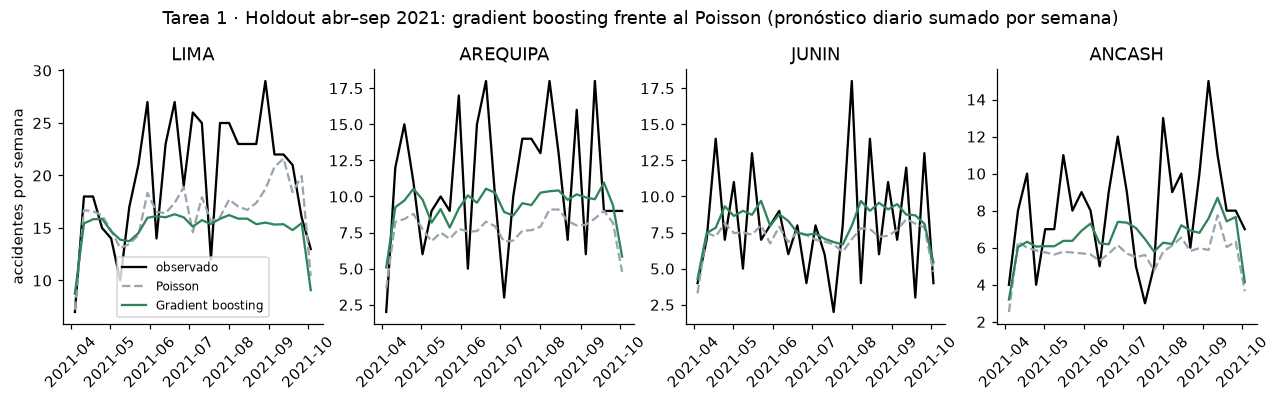

In [5]:
top = panel.groupby("DEPARTAMENTO").N_ACC.sum().nlargest(4).index
sem = te1.assign(POIS=pred_pois, GBM=pred_gbm1).groupby(["DEPARTAMENTO", pd.Grouper(key="FECHA", freq="W")])[["N_ACC", "POIS", "GBM"]].sum()
fig, axs = plt.subplots(1, 4, figsize=(14, 3))
for ax, d in zip(axs, top):
    s = sem.loc[d]
    ax.plot(s.index, s.N_ACC, "k-", lw=1.5, label="observado")
    ax.plot(s.index, s.POIS, "--", color="#9aa5b1", label="Poisson")
    ax.plot(s.index, s.GBM, "-", color="#2f855a", label="Gradient boosting")
    ax.set_title(d); ax.tick_params(axis="x", rotation=45)
axs[0].set_ylabel("accidentes por semana"); axs[0].legend(fontsize=8)
fig.suptitle("Tarea 1 · Holdout abr–sep 2021: gradient boosting frente al Poisson (pronóstico diario sumado por semana)", y=1.06)
guardar(fig, "modelo_13_t1_conteo_gbm_holdout.png")

### 1.2 ¿Habrá algún accidente fatal mañana? (`HAY_FATAL`)
Gradient boosting sin pesos de clase, como la logística del baseline, para que las probabilidades queden calibradas
(Brier). Grilla: tasa de aprendizaje 0.03, 0.1; árboles 50, 150, 400; hojas 7, 15; mínimo por hoja 40, 200; L2 1, 10.
Hay pocos positivos (≈ 6 % de los días), así que la grilla incluye árboles chicos y hojas grandes. Criterio: PR-AUC
media en los pliegues temporales.

In [6]:
grilla = {"clf__learning_rate": [0.03, 0.1],
          "clf__max_iter": [50, 150, 400],
          "clf__max_leaf_nodes": [7, 15],
          "clf__min_samples_leaf": [40, 200],
          "clf__l2_regularization": [1.0, 10.0]}
gbm1b, P1b = ajustar(M.gbm_clasificador(COLS1, class_weight=None), grilla, tr1[X1], tr1.HAY_FATAL, FOLDS1, "average_precision")

48 configuraciones en 95 s · mejor: {'clf__l2_regularization': 10.0, 'clf__learning_rate': 0.03, 'clf__max_iter': 150, 'clf__max_leaf_nodes': 7, 'clf__min_samples_leaf': 200}


,params,mean_test_score,std_test_score
29,"l2_regularization=10.0, learning_rate=0.03, ma...",0.1370,0.0137
13,"l2_regularization=1.0, learning_rate=0.1, max_...",0.1369,0.0169
5,"l2_regularization=1.0, learning_rate=0.03, max...",0.1360,0.0155
3,"l2_regularization=1.0, learning_rate=0.03, max...",0.1350,0.0161
37,"l2_regularization=10.0, learning_rate=0.1, max...",0.1340,0.0152


pr_auc         roc_auc           brier  \
                                     mean     std    mean     std    mean   
Ingenuo · fatales últimos 28 días  0.1119  0.0178  0.6775  0.0140  0.0542   
Baseline · Reg. logística          0.1330  0.0279  0.7041  0.0254  0.0561   
Gradient boosting (ajustado)       0.1370  0.0154  0.7117  0.0158  0.0536   

                                          prevalencia          
                                      std        mean     std  
Ingenuo · fatales últimos 28 días  0.0067      0.0584  0.0081  
Baseline · Reg. logística          0.0076      0.0584  0.0081  
Gradient boosting (ajustado)       0.0065      0.0584  0.0081

GBM − logística (PR-AUC):   +0.004 (IC95% aprox. -0.017 a +0.025), mejor en 1 de 5 pliegues
GBM − ingenuo (PR-AUC):     +0.025 (IC95% aprox. +0.010 a +0.040), mejor en 5 de 5 pliegues


,pr_auc,roc_auc,brier,prevalencia
Ingenuo · fatales últimos 28 días,0.1313,0.6887,0.0618,0.0676
Baseline · Reg. logística,0.1612,0.7335,0.0600,0.0676
Gradient boosting (ajustado),0.1598,0.7354,0.0600,0.0676


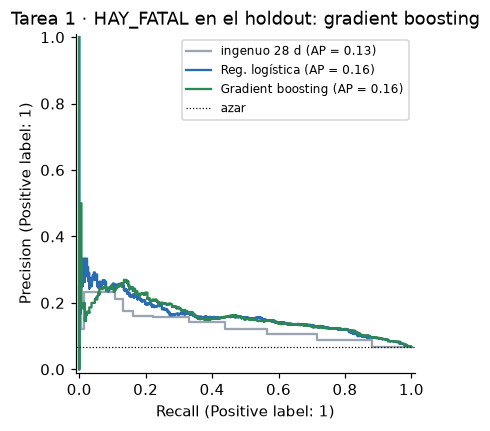

In [7]:
ingenuo_fatal = lambda df: 1 - np.exp(-df.N_FATALES_M28)
logit1 = M.logit(COLS1, class_weight=None)
res1b = {"Ingenuo · fatales últimos 28 días": pd.DataFrame([E.metricas_binaria(tr1.HAY_FATAL.iloc[b], ingenuo_fatal(tr1.iloc[b])) for _, b in FOLDS1]),
         "Baseline · Reg. logística": E.cv_puntajes(logit1, tr1[X1], tr1.HAY_FATAL, FOLDS1, E.metricas_binaria, proba=True),
         GBM: E.cv_puntajes(gbm1b, tr1[X1], tr1.HAY_FATAL, FOLDS1, E.metricas_binaria, proba=True)}
display(resumen(res1b))
print("GBM − logística (PR-AUC):  ", E.comparacion_pareada(res1b[GBM].pr_auc, res1b["Baseline · Reg. logística"].pr_auc))
print("GBM − ingenuo (PR-AUC):    ", E.comparacion_pareada(res1b[GBM].pr_auc, res1b["Ingenuo · fatales últimos 28 días"].pr_auc))

prob_log = clone(logit1).fit(tr1[X1], tr1.HAY_FATAL).predict_proba(te1[X1])[:, 1]
prob_gbm1b = clone(gbm1b).fit(tr1[X1], tr1.HAY_FATAL).predict_proba(te1[X1])[:, 1]
hold1b = {"Ingenuo · fatales últimos 28 días": E.metricas_binaria(te1.HAY_FATAL, ingenuo_fatal(te1)),
          "Baseline · Reg. logística": E.metricas_binaria(te1.HAY_FATAL, prob_log),
          GBM: E.metricas_binaria(te1.HAY_FATAL, prob_gbm1b)}
display(pd.DataFrame(hold1b).T.round(4))
FILAS.append({"tarea": "1_clasificacion_HAY_FATAL", "modelo": GBM, "validacion": "CV temporal (5 pliegues)", **res1b[GBM].mean().to_dict()})
FILAS.append({"tarea": "1_clasificacion_HAY_FATAL", "modelo": GBM, "validacion": "holdout abr-sep 2021", **hold1b[GBM]})

fig, ax = plt.subplots(figsize=(5.5, 4))
PrecisionRecallDisplay.from_predictions(te1.HAY_FATAL, ingenuo_fatal(te1), name="ingenuo 28 d", ax=ax, color="#9aa5b1")
PrecisionRecallDisplay.from_predictions(te1.HAY_FATAL, prob_log, name="Reg. logística", ax=ax, color="#2b6cb0")
PrecisionRecallDisplay.from_predictions(te1.HAY_FATAL, prob_gbm1b, name="Gradient boosting", ax=ax, color="#2f855a")
ax.axhline(te1.HAY_FATAL.mean(), color="k", ls=":", lw=0.8, label="azar")
ax.set_title("Tarea 1 · HAY_FATAL en el holdout: gradient boosting"); ax.legend(fontsize=8)
guardar(fig, "modelo_14_t1_hay_fatal_gbm_holdout.png")

## 2. Tarea 2 · Triaje de gravedad al recibir el reporte
Mismo dataset, mismas variables, mismos 25 pliegues de la CV 5 × 5 y mismo test 80/20 (`random_state=42`).
La grilla se evalúa con `E.CV` **solo dentro del 80 % de entrenamiento**. Criterio: macro-F1.
Grilla: tasa de aprendizaje 0.03, 0.1; árboles 100, 300, 600; hojas 7, 15, 31; mínimo por hoja 20, 40, 100; L2 0, 1.

In [8]:
acc = M.cargar_accidentes()
COLS2 = M.columnas(M.GRUPOS_T2)
X2 = COLS2[0] + COLS2[1]
y2 = acc.GRAVEDAD
tr2, te2 = train_test_split(acc, test_size=0.2, stratify=y2, random_state=M.SEED)
print(f"{len(acc):,} accidentes · {len(X2)} variables ({len(M._separar(COLS2[1])[0])} categóricas nativas) · "
      f"train {len(tr2):,} / test {len(te2):,}")

grilla = {"clf__learning_rate": [0.03, 0.1],
          "clf__max_iter": [100, 300, 600],
          "clf__max_leaf_nodes": [7, 15, 31],
          "clf__min_samples_leaf": [20, 40, 100],
          "clf__l2_regularization": [0.0, 1.0]}
gbm2, P2 = ajustar(M.gbm_clasificador(COLS2), grilla, tr2[X2], tr2.GRAVEDAD, E.CV, "f1_macro")

8,105 accidentes · 29 variables (6 categóricas nativas) · train 6,484 / test 1,621


108 configuraciones en 1433 s · mejor: {'clf__l2_regularization': 0.0, 'clf__learning_rate': 0.03, 'clf__max_iter': 600, 'clf__max_leaf_nodes': 15, 'clf__min_samples_leaf': 20}


,params,mean_test_score,std_test_score
21,"l2_regularization=0.0, learning_rate=0.03, max...",0.4332,0.0198
12,"l2_regularization=0.0, learning_rate=0.03, max...",0.4323,0.0140
70,"l2_regularization=1.0, learning_rate=0.03, max...",0.4321,0.0087
60,"l2_regularization=1.0, learning_rate=0.03, max...",0.4301,0.0082
71,"l2_regularization=1.0, learning_rate=0.03, max...",0.4300,0.0092


In [9]:
FOLDS2 = list(E.CV_REPETIDA.split(acc[X2], y2))
modelo2_avance = M.logit((["ELEVACION", "HORA_SIN", "HORA_COS"], ["DEPARTAMENTO", "MODALIDAD"]))
base2 = M.logit(COLS2)
res2 = {"Dummy (proporciones)": E.cv_puntajes(DummyClassifier(strategy="prior"), acc[X2], y2, FOLDS2, E.metricas_multiclase, proba=True),
        "Modelo 2 del avance (4 variables)": E.cv_puntajes(modelo2_avance, acc[X2], y2, FOLDS2, E.metricas_multiclase, proba=True),
        "Baseline · Reg. logística multinomial": E.cv_puntajes(base2, acc[X2], y2, FOLDS2, E.metricas_multiclase, proba=True),
        GBM: E.cv_puntajes(gbm2, acc[X2], y2, FOLDS2, E.metricas_multiclase, proba=True)}
display(resumen(res2))
for met, mayor in (("macro_f1", True), ("balanced_acc", True), ("pr_auc_fatal", True), ("log_loss", False)):
    print(f"GBM − logística multinomial ({met}):",
          E.comparacion_pareada(res2[GBM][met], res2["Baseline · Reg. logística multinomial"][met], mayor_es_mejor=mayor))
for ref in ("Dummy (proporciones)", "Modelo 2 del avance (4 variables)"):
    print(f"GBM − {ref} (macro_f1):", E.comparacion_pareada(res2[GBM].macro_f1, res2[ref].macro_f1))
FILAS.append({"tarea": "2_triaje_GRAVEDAD", "modelo": GBM, "validacion": "CV estratificada 5x5", **res2[GBM].mean().to_dict()})

macro_f1         balanced_acc          \
                                          mean     std         mean     std   
Dummy (proporciones)                    0.2278  0.0001       0.3333  0.0000   
Modelo 2 del avance (4 variables)       0.4213  0.0095       0.4690  0.0119   
Baseline · Reg. logística multinomial   0.4190  0.0078       0.4656  0.0096   
Gradient boosting (ajustado)            0.4321  0.0107       0.4413  0.0123   

                                      pr_auc_fatal         log_loss          
                                              mean     std     mean     std  
Dummy (proporciones)                        0.1173  0.0003   0.9596  0.0003  
Modelo 2 del avance (4 variables)           0.2694  0.0256   1.0372  0.0069  
Baseline · Reg. logística multinomial       0.2655  0.0269   1.0371  0.0088  
Gradient boosting (ajustado)                0.2357  0.0195   1.0116  0.0136

GBM − logística multinomial (macro_f1): +0.013 (IC95% aprox. +0.008 a +0.018), mejor en 21 de 25 pliegues
GBM − logística multinomial (balanced_acc): -0.024 (IC95% aprox. -0.031 a -0.018), mejor en 3 de 25 pliegues
GBM − logística multinomial (pr_auc_fatal): -0.030 (IC95% aprox. -0.039 a -0.021), mejor en 3 de 25 pliegues
GBM − logística multinomial (log_loss): -0.026 (IC95% aprox. -0.030 a -0.021), mejor en 25 de 25 pliegues
GBM − Dummy (proporciones) (macro_f1): +0.204 (IC95% aprox. +0.200 a +0.208), mejor en 25 de 25 pliegues
GBM − Modelo 2 del avance (4 variables) (macro_f1): +0.011 (IC95% aprox. +0.006 a +0.015), mejor en 23 de 25 pliegues


### 2.1 Test 80/20: matriz de confusión

,macro_f1,balanced_acc,pr_auc_fatal,log_loss
Baseline · Reg. logística multinomial,0.4360,0.4836,0.2597,1.0191
Gradient boosting (ajustado),0.4271,0.4330,0.2271,0.9977


              precision    recall  f1-score   support

sin víctimas      0.481     0.478     0.480       590
     heridos      0.582     0.542     0.561       841
       fatal      0.211     0.279     0.240       190

    accuracy                          0.488      1621
   macro avg      0.425     0.433     0.427      1621
weighted avg      0.502     0.488     0.494      1621



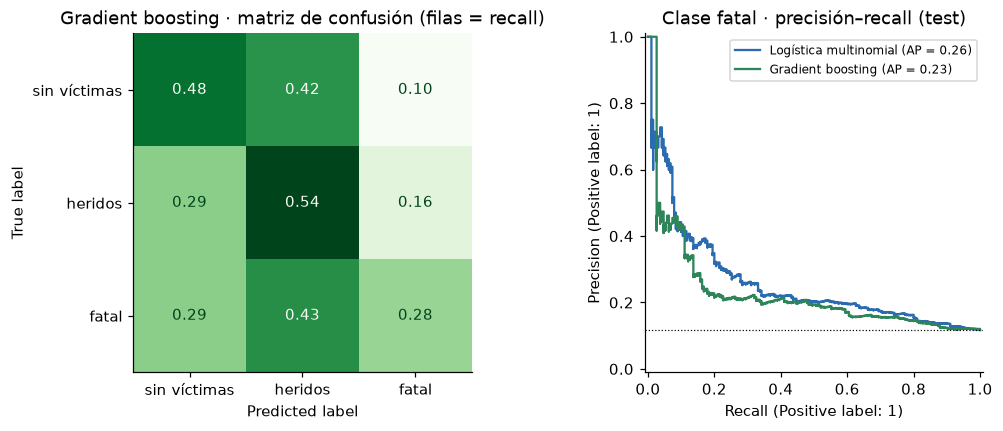

In [10]:
proba_log2 = clone(base2).fit(tr2[X2], tr2.GRAVEDAD).predict_proba(te2[X2])
proba_gbm2 = clone(gbm2).fit(tr2[X2], tr2.GRAVEDAD).predict_proba(te2[X2])
hold2 = {"Baseline · Reg. logística multinomial": E.metricas_multiclase(te2.GRAVEDAD, proba_log2),
         GBM: E.metricas_multiclase(te2.GRAVEDAD, proba_gbm2)}
display(pd.DataFrame(hold2).T.round(4))
print(classification_report(te2.GRAVEDAD, proba_gbm2.argmax(1), target_names=M.CLASES_T2, digits=3))
FILAS.append({"tarea": "2_triaje_GRAVEDAD", "modelo": GBM, "validacion": "test estratificado 80/20", **hold2[GBM]})

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(te2.GRAVEDAD, proba_gbm2.argmax(1), display_labels=M.CLASES_T2, normalize="true",
                                        values_format=".2f", cmap="Greens", ax=axs[0], colorbar=False)
axs[0].set_title("Gradient boosting · matriz de confusión (filas = recall)")
PrecisionRecallDisplay.from_predictions(te2.GRAVEDAD == 2, proba_log2[:, 2], name="Logística multinomial", ax=axs[1], color="#2b6cb0")
PrecisionRecallDisplay.from_predictions(te2.GRAVEDAD == 2, proba_gbm2[:, 2], name="Gradient boosting", ax=axs[1], color="#2f855a")
axs[1].axhline((te2.GRAVEDAD == 2).mean(), color="k", ls=":", lw=0.8)
axs[1].set_title("Clase fatal · precisión–recall (test)"); axs[1].legend(fontsize=8)
guardar(fig, "modelo_15_t2_gbm_test.png")

## 3. ¿Depende de la semilla?
En el MLP la inicialización de los pesos movía el resultado tanto como la diferencia con el baseline. Aquí no hace
falta repetir con varias semillas: sin early stopping ni submuestreo, `HistGradientBoosting` es **determinista** (la
semilla solo se usa para separar la validación del early stopping y para submuestrear los bins con más de 200 000
filas). Se comprueba reentrenando con otra semilla:

In [11]:
def con_semilla(modelo, s):
    clave = [k for k in modelo.get_params() if k.endswith("random_state")][0]
    return clone(modelo).set_params(**{clave: s})

assert np.allclose(con_semilla(gbm1, 7).fit(tr1[X1], tr1.N_ACC).predict(te1[X1]), pred_gbm1)
assert np.allclose(con_semilla(gbm2, 7).fit(tr2[X2], tr2.GRAVEDAD).predict_proba(te2[X2]), proba_gbm2)
print("Mismas predicciones con random_state=7 que con 42: el resultado no depende de la semilla.")

Mismas predicciones con random_state=7 que con 42: el resultado no depende de la semilla.


## 4. Resultados guardados
Se agregan las filas del gradient boosting a `results/metrics.csv` (mismo esquema que el baseline; si ya existían, se
reemplazan). Las referencias no se vuelven a guardar: ya las escriben `02_modelos.ipynb` y `05_binomial_negativa.ipynb`.
Configuraciones elegidas:

In [12]:
print("Tarea 1 · N_ACC:    ", config(P1))
print("Tarea 1 · HAY_FATAL:", config(P1b))
print("Tarea 2 · GRAVEDAD: ", config(P2))
f_metrics = ROOT / "results" / "metrics.csv"
nuevas = pd.DataFrame(FILAS)
previas = pd.read_csv(f_metrics)
clave = ["tarea", "modelo", "validacion"]
previas = previas[~previas.set_index(clave).index.isin(nuevas.set_index(clave).index)]   # reemplaza si ya existían
pd.concat([previas, nuevas], ignore_index=True).to_csv(f_metrics, index=False)
print(f"{len(nuevas)} filas guardadas en {f_metrics.name}")
nuevas.round(4)

Tarea 1 · N_ACC:     l2_regularization=1.0, learning_rate=0.03, max_iter=100, max_leaf_nodes=7, min_samples_leaf=100
Tarea 1 · HAY_FATAL: l2_regularization=10.0, learning_rate=0.03, max_iter=150, max_leaf_nodes=7, min_samples_leaf=200
Tarea 2 · GRAVEDAD:  l2_regularization=0.0, learning_rate=0.03, max_iter=600, max_leaf_nodes=15, min_samples_leaf=20
6 filas guardadas en metrics.csv


,tarea,modelo,validacion,poisson_dev,d2_poisson,mae,rmse,pr_auc,roc_auc,brier,prevalencia,macro_f1,balanced_acc,pr_auc_fatal,log_loss
0,1_conteo_N_ACC,Gradient boosting (ajustado),CV temporal (5 pliegues),0.9374,0.2668,0.559,0.7813,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1_conteo_N_ACC,Gradient boosting (ajustado),holdout abr-sep 2021,0.9857,0.2892,0.602,0.8457,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1_clasificacion_HAY_FATAL,Gradient boosting (ajustado),CV temporal (5 pliegues),NaN,NaN,NaN,NaN,0.1370,0.7117,0.0536,0.0584,NaN,NaN,NaN,NaN
3,1_clasificacion_HAY_FATAL,Gradient boosting (ajustado),holdout abr-sep 2021,NaN,NaN,NaN,NaN,0.1598,0.7354,0.0600,0.0676,NaN,NaN,NaN,NaN
4,2_triaje_GRAVEDAD,Gradient boosting (ajustado),CV estratificada 5x5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.4321,0.4413,0.2357,1.0116
5,2_triaje_GRAVEDAD,Gradient boosting (ajustado),test estratificado 80/20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.4271,0.4330,0.2271,0.9977


## Lectura
- **Tarea 1 · `N_ACC`:** el mejor promedio en CV de todos los modelos (D² 0.267 frente a 0.256 del Poisson), pero la
  diferencia no es significativa (+0.011, IC −0.013 a +0.035, mejor en 3 de 5 pliegues). Le gana a la media de 28 días
  en los 5 pliegues (+0.050). En el holdout abr–sep 2021 supera a la media de 28 días (0.289 frente a 0.277; Poisson
  0.267), igual que el MLP (0.292). Que **dos modelos no lineales distintos** sigan mejor la subida de accidentes tras
  la cuarentena (figura `modelo_13`: Arequipa, Áncash y Junín) confirma la señal que se vio con el MLP. En Lima, en
  cambio, se queda corto en agosto–septiembre, como el Poisson.
- **Tarea 1 · `HAY_FATAL`:** empate con la logística. PR-AUC 0.137 frente a 0.133 en CV (+0.004, IC con el 0, mejor en
  1 de 5 pliegues) y 0.160 frente a 0.161 en el holdout, con la misma ROC-AUC (0.735 frente a 0.734) y el mismo Brier.
- **Hiperparámetros de la Tarea 1:** en las dos variables la grilla eligió el modelo **más simple y regularizado** que
  probó (100–150 árboles con tasa 0.03, 7 hojas, 100–200 casos por hoja). Con 10 776 departamento-días, la señal más
  allá de la historia reciente es débil y un modelo más flexible sobreajusta.
- **Tarea 2 · `GRAVEDAD`:** es el primer modelo que supera a la logística multinomial en macro-F1 con un IC que no
  incluye el 0 (0.432 frente a 0.419; +0.013, IC +0.008 a +0.018, mejor en 21 de 25 pliegues). También tiene mejor
  log-loss (1.012 frente a 1.037, mejor en 25 de 25 pliegues). Pero ordena **peor a los fatales** (PR-AUC −0.030, peor
  en 22 de 25 pliegues) y tiene menor balanced accuracy (−0.024). Clasifica mejor sin víctimas y heridos, y a cambio
  detecta menos fatales: en el test su recall de fatales es 0.28, frente a 0.51 de la logística. En el único test 80/20
  su macro-F1 queda por debajo (0.427 frente a 0.436), dentro de la variación entre pliegues (± 0.011).
- **Para el triaje**, dejar pasar un accidente fatal cuesta más que confundir heridos con sin víctimas, así que la
  logística sigue siendo preferible para detectar fatales. El gradient boosting gana en las clases frecuentes. Esto
  justifica probar el ensamble por votación (#10), que puede combinar las dos fortalezas.
- **Frente a Babaoglu y Babaoglu (2021):** su XGBoost llega al 83 % de exactitud, pero con otra base de datos y
  midiendo la exactitud, que aquí no se usa. Con 8 105 accidentes sin variables del vehículo ni de las personas, el
  boosting aporta poco sobre el modelo lineal.
- **Semilla:** sin early stopping el modelo es determinista, así que, a diferencia del MLP, sus diferencias con el
  baseline no se deben a la inicialización.